In [7]:
# Purpose - plot spectra from one file

findex = 250 #230 #-7 #190 #170

In [8]:
# Imports and Folder Selection

from graphet import Data
from graphet.plugins import TristanV2 
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
import sys
sys.path.append('../../v2_proc_files')
from useful_funcs import *
from TristanRun import TristanRun

%matplotlib widget

%load_ext autoreload
%autoreload 2 

set_standard_plot_params()

# Read Input File Data

run = TristanRun(findex)
boilerplate = "TODO" #run.boilerplate + f"tstep = {run.steps[0]}"
my_steps = run.steps[:-1]

d = run.config_data(my_steps, mode = "spectra")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
{ Graph-ET Data Container }

Plugin: TristanV2

Steps: 0...282 [283]
Times: 0.00...125404073.46

* Spectra:
  - Keys: ['n1', 'n2', 'n3', 'n4']




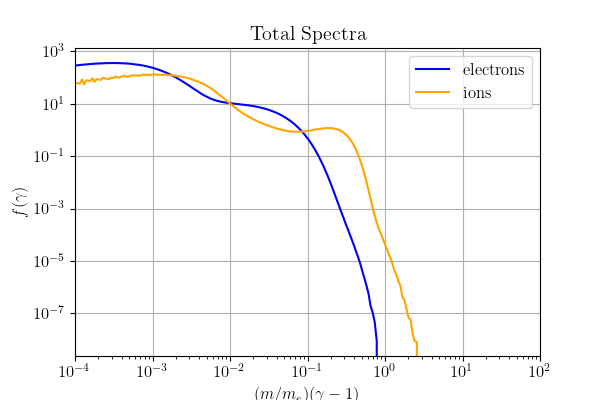

In [13]:
species_dict = {1: 'electrons', 2: 'ions'}
mass_dict = {1: 1, 2: run.mime}
ADJUST_MASS = True

colors = ['blue', 'orange']

alfven_speed = np.sqrt(run.sigma * 2 / (mass_dict[1] + mass_dict[2])) # in units of c

species = 1
species_name = species_dict[species]
mass = mass_dict[species]
tses = [100, my_steps[-1]]
tses = [100]
tses = [my_steps[-1]]

# Normalize counts to get probability density

plt.figure(figsize=(6, 4))

for i in [1, 2]:
    for j in range(len(tses)):
        ts = tses[j]
        mass = mass_dict[i]
        color = colors[i - 1]

        alpha = j * 0.6 + 0.4
        alpha = 1

        ebins, spectrum = TristanRun.get_spectrum(d, ts, i)
        if (ADJUST_MASS):
            plt.loglog(ebins * mass, spectrum / mass, label = species_dict[i], color = color, alpha = alpha) #f" t = {ts}"
        else:
            plt.loglog(ebins, spectrum, label = species_dict[i], color = color, alpha = alpha) #f" t = {ts}"

        pickup = mass * alfven_speed ** 2
        #plt.axvline(pickup, linestyle = '--', color = color, alpha = 0.3)

if (ADJUST_MASS):
    plt.xlabel(f"$(m / m_e) (\\gamma - 1)$")
else:
    plt.xlabel("$\\gamma - 1$")
plt.ylabel("$f(\\gamma)$")

technical_title = run.boilerplate + f"\nmime = {run.mime}"

plt.title("Total Spectra")

metadata = {"info": technical_title}

plt.xlim([1e-4, 1e2])

save_polished_fig("total_spectra_04_28_26.png", dpi = 300, metadata = metadata) 

plt.legend()
plt.grid()
plt.show()

In [14]:
# Percent of total kinetic energy in electrons vs ions (at latest timestep)
ts = run.steps[-1] - 1

energy_by_species = {}

for sp in [1, 2]:
    eb, spec = TristanRun.get_spectrum(d, ts, sp)
    m = mass_dict[sp]

    # Kinetic energy density in each bin: m * (gamma - 1) * f(gamma)
    # Integrate over (gamma - 1)
    e_kin = np.trapz(m * eb * spec, eb)
    energy_by_species[sp] = e_kin

total_energy = energy_by_species[1] + energy_by_species[2]

electron_pct = 100 * energy_by_species[1] / total_energy
ion_pct = 100 * energy_by_species[2] / total_energy

print(f"t = {ts}")
print(f"Electrons: {electron_pct:.2f}%")
print(f"Ions:      {ion_pct:.2f}%")

t = 282
Electrons: 16.76%
Ions:      83.24%


In [15]:
print(83.2 / 16.76)

4.964200477326969


NameError: name 'runs' is not defined

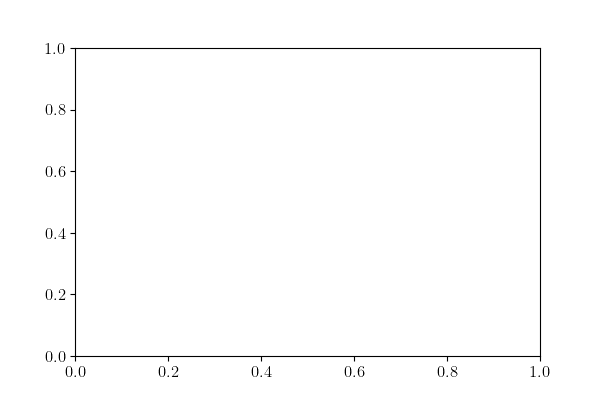

In [12]:
# Plot Domain and Spectrum

species = 1

plt.close()
fig, ax1 = plt.subplots(nrows = 1, ncols = 1, figsize = (6, 4))

colors = plt.cm.viridis(np.linspace(0, 1, len(runs)))
colors = ['red', 'blue']

tot_normalize = True

for i, run in enumerate(runs):
    label = True
    xcoeff = 1 / run.sigma

    d = run.config_data(run.steps, mode = "spectra")

    bs = d.spectra.isel(t = run.steps[-1])

    yvals = bs.calc_hist()

    if (not tot_normalize):
        yvals *= bs.total

    if (label):
        ax1.loglog(bs.ebins * xcoeff, yvals, linewidth = 1,
                markersize = 1.5, label = f'$\sigma = $ {run.sigma}')

    else:
        ax1.loglog(bs.ebins * xcoeff, bs.calc_hist() * bs.total, linewidth = 1,
                markersize = 1.5, color=colors[i])

plt.suptitle("")

line_values = { #in gamma 
    'sigma': 1 + run.sigma,
    '1': 2,
    #'gamma_A': (1 - run.beta_A ** 2) ** -0.5,
    'gamma_spec': (1 + run.beta_A ** 2) / (1 - run.beta_A ** 2)
}

line_values = {}

line_colors = { #in gamma 
    'sigma': 'black',
    '1': 'black',
    'gamma_A': 'cyan',
    'gamma_spec': 'purple'
}

for line in line_values:

    ax1.axvline((line_values[line] - 1) * xcoeff, color = line_colors[line] , linestyle = '--', alpha = 0.5, label = line)

title = "Electron Spectra"

#for i in range(len(runs)):
    #title += f"\n {runs[i].code}, $\gamma_{{mean}} - 1 = {means[i]:.2f}, p = {probs[i]:.2e}$"

ax1.set_title(title)
ax1.grid(visible = True)
ax1.set_xlim([1e-4, 1e2])

#ax1.axvspan(interval[0], interval[1], color='yellow', alpha=0.3, label='Interval')

#ax2.set_ylim([1, 1e12])
ax1.legend()
#ax2.loglog(spec_bins, spec_counts, linewidth = 1, markersize = 1.5)

plt.xlabel("$(\gamma - 1) / \sigma$")  

if (tot_normalize):
    plt.ylabel("$f(\gamma)$")
else:
    plt.ylabel("$dN / d\gamma$")

plt.xlim([1e-3, 1e2])

plt.tight_layout()
#save_plot("spectra", dpi = 400)

plt.show()

In [ ]:
print(run.spec_nx)
print(run.spec_ny)

In [ ]:
print(0 / 0)

In [ ]:
# Close any existing plots
plt.close()

# Create a new figure and axis
fig, ax2 = plt.subplots(nrows=1, ncols=1, figsize=(6, 4))

# Iterate over each run
for i, run in enumerate(runs):
    cutoffs = []
    timesteps = run.steps

    # Calculate the energy cutoff for each timestep
    for sel_ts in timesteps:
        bs = run.find_total_spectrum(sel_ts, species)

        cutoff = bs.calc_cutoff()
        cutoffs.append(cutoff)

    # Plot the energy cutoff vs. timestep
    ax2.plot(timesteps, cutoffs, label=f'Run {run.code}', color=colors[i])

# Set axis labels and title
ax2.set_xlabel('$t \Omega$')
ax2.set_ylabel('Energy Cutoff ($\gamma - 1$)')
ax2.set_title('Energy Cutoff vs. Timestep')
ax2.grid(visible=True)
ax2.legend()

# Show the plot
plt.show()